# Chapter 1: A classical detector (SIFT + RANSAC)

A copied region has the same texture as its source, so its keypoints have near-identical
descriptors at a consistent offset. This notebook walks one image through the detector,
then shows how the tuning sweep chose its settings.
All logic lives in the `forgery` package; this notebook only calls it and plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from forgery.classical import compute_features, draw_masks, group, match, prepare
from forgery.data import build_index, load_image, load_masks
from forgery.metric import score_image
from forgery.split import REPO_ROOT, get_slice

index = build_index()
tune = get_slice("tune", index)
chosen = yaml.safe_load((REPO_ROOT / "configs" / "01_sift.yaml").read_text())["predictor"]["params"]
print("chosen setting:", chosen)

chosen setting: {'max_side': 1024, 'min_distance': 10, 'ransac': True, 'ransac_threshold': 3.0, 'max_groups': 4, 'clahe': True, 'ratio': 0.4, 'min_inliers': 6, 'pad': 10}


## 1. One image, step by step

A forged image from the tuning slice (never validation) that the chosen setting gets right.

In [2]:
def run_steps(image):
    f = compute_features(image, chosen["max_side"], chosen["clahe"])
    pairs = match(f, chosen["ratio"], chosen["min_distance"])
    groups = group(f.points, pairs, chosen["ransac_threshold"], chosen["min_inliers"], chosen["max_groups"])
    masks = draw_masks(f.points, groups, f.scale, f.shape, chosen["pad"])
    return f, pairs, groups, masks


forged = tune[tune.source == "forged"]
for row in forged.itertuples():
    image, gt = load_image(row.image_path), load_masks(row.mask_path)
    f, pairs, groups, masks = run_steps(image)
    if len(gt) == 2 and len(masks) == 2 and score_image(masks, gt) > 0.8:
        break
print(f"case {row.case_id}: {len(f.points)} keypoints, {len(pairs)} matches, {len(groups)} groups, "
      f"score {score_image(masks, gt):.3f}")

case 3073: 10981 keypoints, 76 matches, 2 groups, score 0.902


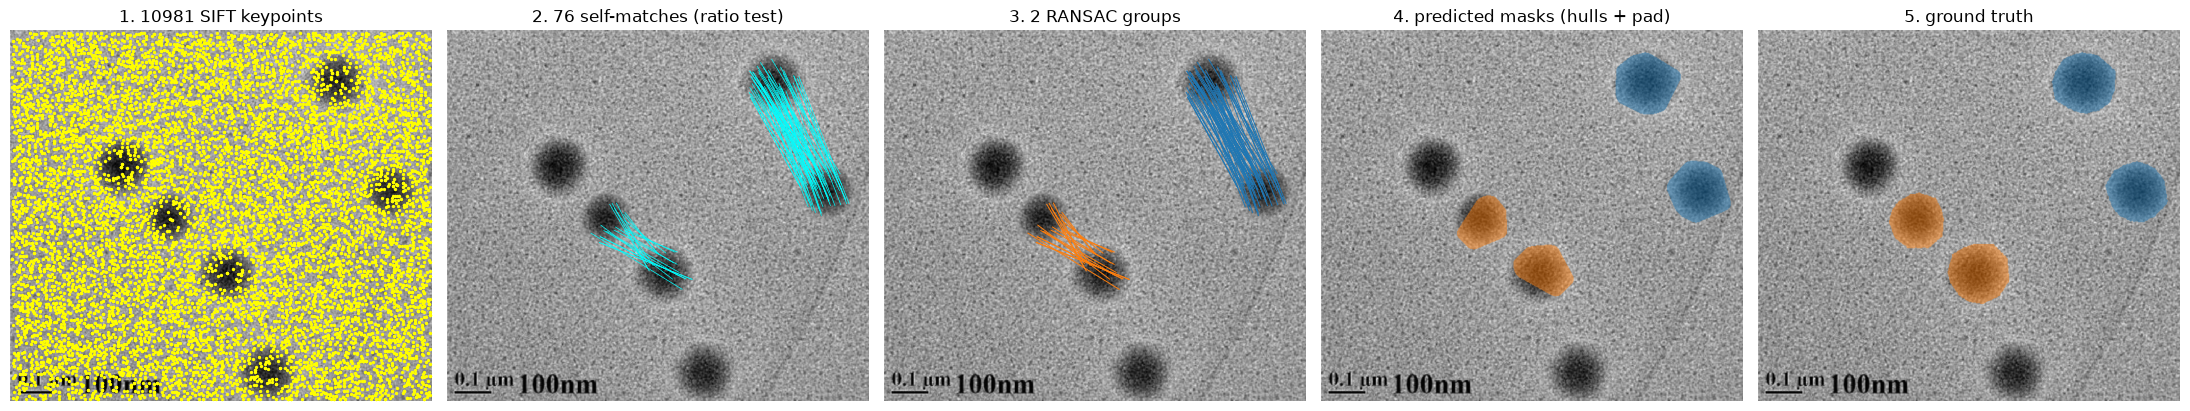

In [3]:
def overlay(image, masks):
    out = image.astype(float) / 255
    colours = plt.cm.tab10.colors
    for k, m in enumerate(masks):
        out[m > 0] = 0.5 * out[m > 0] + 0.5 * np.array(colours[k % 10])
    return out


xy = f.points / f.scale  # back to original-image px
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
axes[0].imshow(image)
axes[0].scatter(xy[:, 0], xy[:, 1], s=2, c="yellow")
axes[0].set_title(f"1. {len(xy)} SIFT keypoints")
axes[1].imshow(image)
for i, j in pairs:
    axes[1].plot(*xy[[i, j]].T, lw=0.5, c="cyan")
axes[1].set_title(f"2. {len(pairs)} self-matches (ratio test)")
axes[2].imshow(image)
for k, g in enumerate(groups):
    for i, j in g:
        axes[2].plot(*xy[[i, j]].T, lw=0.7, c=plt.cm.tab10.colors[k])
axes[2].set_title(f"3. {len(groups)} RANSAC groups")
axes[3].imshow(overlay(image, masks))
axes[3].set_title("4. predicted masks (hulls + pad)")
axes[4].imshow(overlay(image, gt))
axes[4].set_title("5. ground truth")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

Each group's mask is one layer covering both the source and the copy, the same way the
ground truth marks a duplication. Matches that RANSAC can't explain with one movement are
dropped, which is what keeps scattered coincidental matches from becoming false masks.

## 2. Tuning: how the score moves with each knob

All 160 settings were scored on the tuning slice (`experiments/tuning/01_sift.csv`). Each
plot shows, for each value of one knob, the best score over all the other knobs.

160 settings, 1027 images, commit 08aacd3


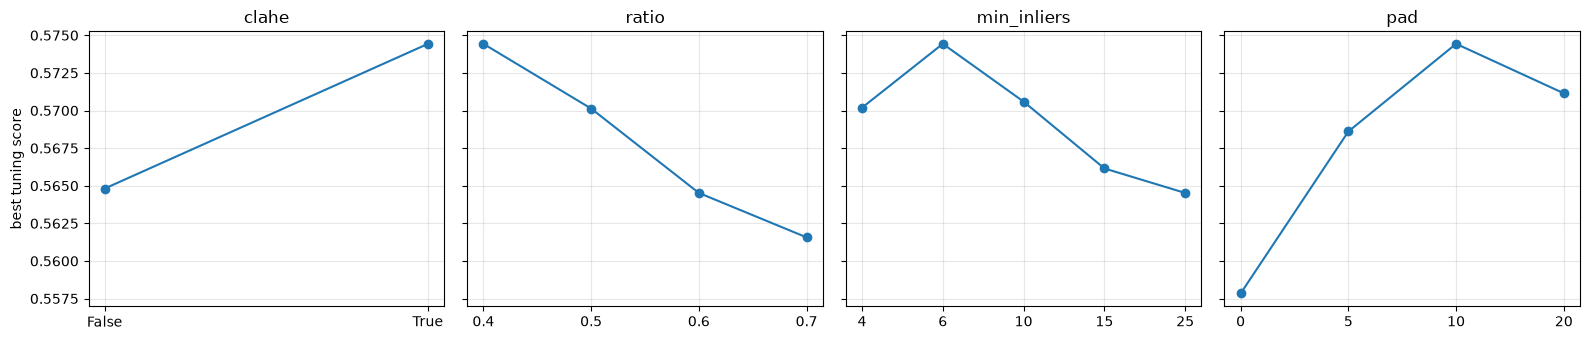

In [4]:
log = pd.read_csv(REPO_ROOT / "experiments" / "tuning" / "01_sift.csv")
print(f"{len(log)} settings, {log.n_images.iloc[0]} images, commit {log.git_commit.iloc[0]}")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, knob in zip(axes, ["clahe", "ratio", "min_inliers", "pad"]):
    best = log.groupby(knob).score.max()
    ax.plot([str(v) for v in best.index], best.values, marker="o")
    ax.set_title(knob)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("best tuning score")
plt.tight_layout()

In [5]:
columns = ["clahe", "ratio", "min_inliers", "pad", "score", "acc_authentic", "recall_forged", "mean_of1_detected"]
print("Best setting with CLAHE off and on:")
log.loc[log.groupby("clahe").score.idxmax(), columns]

Best setting with CLAHE off and on:


,clahe,ratio,min_inliers,pad,score,acc_authentic,recall_forged,mean_of1_detected
6,False,0.4,6,10,0.564817,0.985294,0.257713,0.782160
86,True,0.4,6,10,0.574433,0.989496,0.277677,0.777405


In [6]:
print("Top 10 settings:")
log.sort_values("score", ascending=False).head(10)[columns]

Top 10 settings:


,clahe,ratio,min_inliers,pad,score,acc_authentic,recall_forged,mean_of1_detected
86,True,0.4,6,10,0.574433,0.989496,0.277677,0.777405
87,True,0.4,6,20,0.571143,0.989496,0.277677,0.755321
90,True,0.4,10,10,0.570589,0.995798,0.237750,0.854926
82,True,0.4,4,10,0.570188,0.974790,0.306715,0.719424
110,True,0.5,10,10,0.570130,0.987395,0.250454,0.837129
106,True,0.5,6,10,0.570001,0.974790,0.295826,0.744733
85,True,0.4,6,5,0.568608,0.989496,0.277677,0.738303
83,True,0.4,4,20,0.567426,0.974790,0.306715,0.702644
109,True,0.5,10,5,0.566937,0.987395,0.250454,0.813364
89,True,0.4,10,5,0.566412,0.995798,0.237750,0.822178
